<a href="https://colab.research.google.com/github/fermy0n/Analytical-Mechanics-Double-Pendulum/blob/main/Mec%C3%A1nica_Anal%C3%ADtica_P%C3%A9ndulo_Doble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0.01 3.073484074561779e-08
0.005 1.1223953242641128e-09


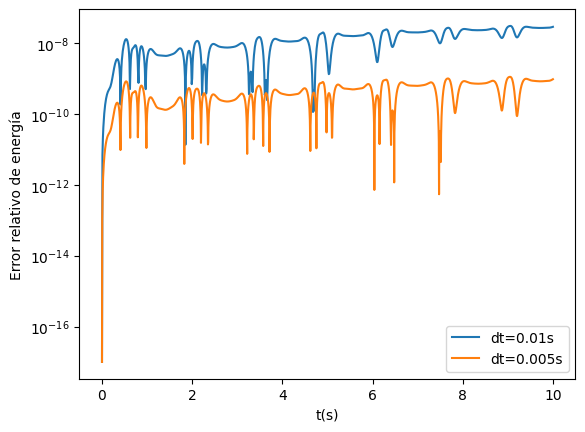

λ: [3.41421356 0.58578644] Teórico  3.414213562373095 0.5857864376269049
θ₂/θ₁:  [-1.41421356  1.41421356] Teórico: -1.4142135623730951 1.4142135623730951
diferencia máxima θ₁: 0.00025635847641134173
diferencia máxima θ₂: 0.00035866746084961044
0.02 -0.01


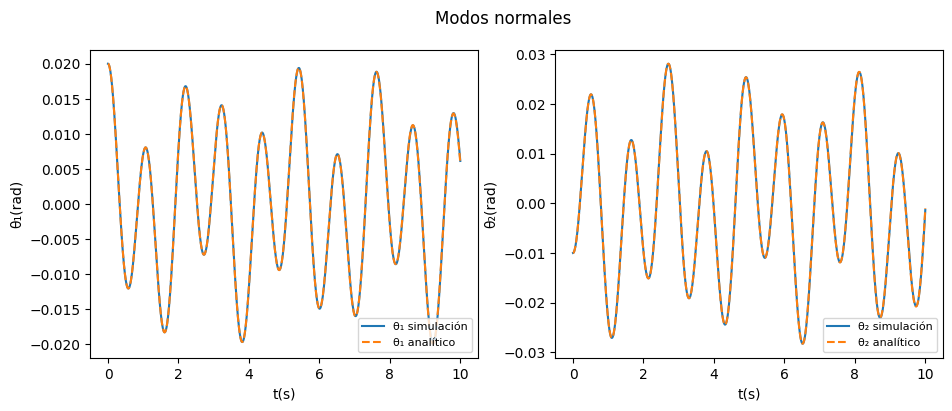

θ₀=0.3, E=-28.12, λ≈0.0181/s
θ₀=1, E=-15.90, λ≈0.0371/s
θ₀=1.5, E=-2.08, λ≈0.8291/s
θ₀=2.5, E=23.58, λ≈1.4141/s


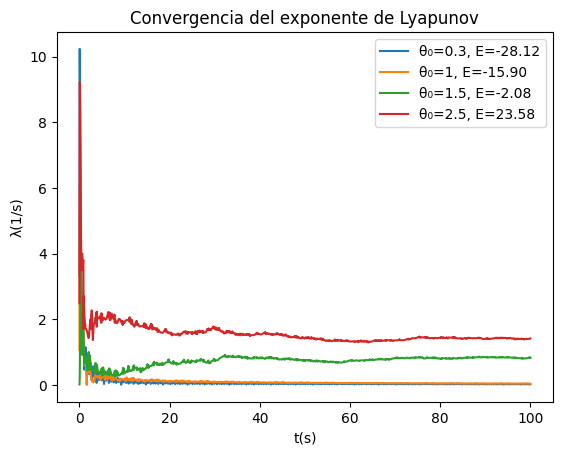

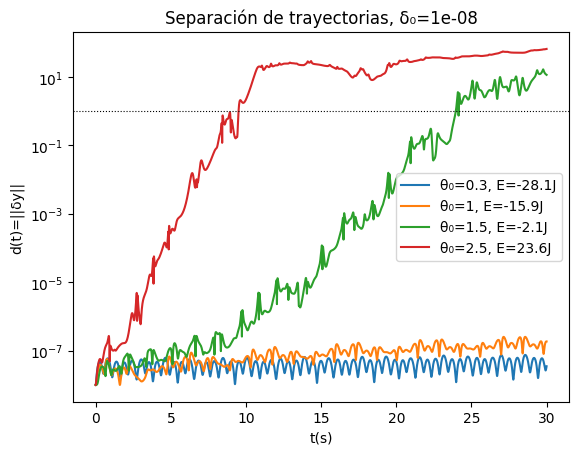

  th0     E(J)   λ ajuste  λ Benettin    t_h(s)
 0.30   -28.12      0.007       0.018       inf
 1.00   -15.90      0.063       0.037       inf
 1.50    -2.08      0.627       0.829      22.2
 2.50    23.58      1.995       1.414      13.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import LineCollection

m1=1
m2=1
l1=1
l2=1
g=9.81

def f(y):
  theta1, theta2, w1, w2 = y
  delta=(theta1-theta2)
  M=np.array([[(m1+m2)*l1, m2*l2*np.cos(delta)],
   [l1*np.cos(delta), l2]])
  b= np.array([-m2*l2*(w2**2)*np.sin(delta)-(m1+m2)*g*np.sin(theta1),
   l1*(w1**2)*np.sin(delta)-g*np.sin(theta2)])
  wp1, wp2= np.linalg.solve(M,b)
  return np.array([w1, w2, wp1, wp2])

def rk4(y, dt):
  k1= f(y)
  k2= f(y+k1*(dt/2))
  k3= f(y+k2*(dt/2))
  k4= f(y+k3*dt)
  return y+(dt/6)*(k1+2*k2+2*k3+k4)

def energia(y):
  theta1, theta2, w1, w2=y
  delta=(theta1-theta2)
  T=((1/2)*m1*(l1**2)*(w1**2))+((1/2)*m2)*((l1**2)*(w1**2)+(l2**2)*(w2**2)+2*l1*l2*w1*w2*np.cos(delta))
  V=-(m1+m2)*g*l1*np.cos(theta1)-m2*g*l2*np.cos(theta2)
  return T+V

def simulacion(y0, dt, T):
  N=int(T/dt)
  yn=np.zeros((N+1, 4))
  yn[0]=y0
  for i in range(N):
    yn[i+1]=rk4(yn[i], dt)
  return np.arange(N+1)*dt, yn

y0=np.array([np.pi/3, np.pi/3, 0, 0])

error={}
for dt in (0.01, 0.005):
  t,yn= simulacion(y0, dt, 10)
  E=np.array([energia(y) for y in yn])
  error[dt]=np.max(np.abs(((E-E[0])/E[0])))
  print(dt, error[dt])

plt.figure()
for dt in (0.01, 0.005):
  t,yn= simulacion(y0, dt, 10)
  E=np.array([energia(y) for y in yn])
  plt.semilogy(t, np.abs((E-E[0])/E[0])+1e-17, label=f"dt={dt}s")
plt.xlabel("t(s)")
plt.ylabel("Error relativo de energía")
plt.legend()
plt.show()

#MODOS NORMALES SIMÉTRICOS:, solo para l1=l2=l, m1=m2=m
w0=np.sqrt(g/l1)
w1=np.sqrt(2+np.sqrt(2))*w0 #caso rápido
w2=np.sqrt(2-np.sqrt(2))*w0 #caso lento

M=np.array([[2,1],[1,1]])
K=np.array([[2,0],[0,1]])
value, vector= np.linalg.eig(np.linalg.inv(M)@(K))
print("λ:", value, "Teórico ", 2+np.sqrt(2), 2-np.sqrt(2))
print("θ₂/θ₁: ",vector[1]/vector[0], "Teórico:",-np.sqrt(2), np.sqrt(2))

theta1=0.02
theta2=-0.01
c1=(theta1-theta2/np.sqrt(2))/2
c2=(theta1+theta2/np.sqrt(2))/2

t,yn=simulacion(np.array([theta1, theta2, 0, 0]), 0.005, 10)
theta1an=c1*np.cos(w1*t)+c2*np.cos(w2*t)
theta2an=np.sqrt(2)*(-c1*np.cos(w1*t)+c2*np.cos(w2*t))
print("diferencia máxima θ₁:", np.max(np.abs(yn[:, 0]-theta1an)))
print("diferencia máxima θ₂:", np.max(np.abs(yn[:, 1]-theta2an)))
print(theta1an[0], theta2an[0])
fig, axs= plt.subplots(1, 2, figsize=(11,4))
for ax, k, an, nombre, in zip(axs, (0,1), (theta1an, theta2an),("θ₁","θ₂")):
  ax.plot(t, yn[:, k], label=f"{nombre} simulación")
  ax.plot(t, an, "--", label=f"{nombre} analítico")
  ax.set_xlabel("t(s)")
  ax.set_ylabel(f"{nombre}(rad)")
  ax.legend(fontsize=8, loc="lower right")
plt.suptitle(f"Modos normales")
plt.show()

def lyapunov(y0, dt=0.01, T=100, d0=1e-8):
  n=int(T/dt)
  ya=np.array(y0, dtype=float)
  yb=ya+np.array([d0, 0, 0, 0])
  suma=0
  lam_t=np.zeros(n)
  for i in range(n):
    ya=rk4(ya, dt)
    yb=rk4(yb, dt)
    d=np.linalg.norm(yb-ya)
    suma+=np.log(d/d0)
    yb=ya+(yb-ya)*d0/d
    lam_t[i]=suma/((i+1)*dt)
  return np.arange(1, n+1)*dt, lam_t

plt.figure()
for th0 in(0.3, 1, 1.5, 2.5):
  y0L=np.array([th0, th0, 0, 0])
  tL, lamL=lyapunov(y0L)
  print(f"θ₀={th0}, E={energia(y0L):.2f}, λ≈{lamL[-1]:.3f}1/s")
  plt.plot(tL, lamL, label=f"θ₀={th0}, E={energia(y0L):.2f}")
plt.xlabel("t(s)")
plt.ylabel("λ(1/s)")
plt.title("Convergencia del exponente de Lyapunov")
plt.legend()
plt.show()


#IA hizo todo esto de la imagen
def separacion(y0, dt=0.005, T=30, d0=1e-8):
  n=int(T/dt)
  ya=np.array(y0,dtype=float)
  yb=ya+np.array([d0, 0, 0, 0])
  dsep=np.zeros(n+1)
  dsep[0]=d0
  for i in range (n):
    ya=rk4(ya, dt)
    yb=rk4(yb, dt)
    dsep[i+1]=np.linalg.norm(yb-ya)
  return np.arange(n+1)*dt, dsep

def lyapunov_2(t, dsep, dmin=2e-8, dmax=1e-2):
  mascara=(dsep>dmin)&(dsep<dmax)
  if mascara.sum()<10:
    return np.nan
  return np.polyfit(t[mascara], np.log(dsep[mascara]), 1)[0]

casos_lyap=(0.3, 1, 1.5, 2.5)
d0sep=1e-8
tol=1
filas=[]

plt.figure()
for th0 in casos_lyap:
  y0s=np.array([th0, th0, 0, 0])
  ES=energia(y0s)
  tS, dS=separacion(y0s, d0=d0sep)
  lamajuste=lyapunov_2(tS, dS)
  lambenettin=lyapunov(y0s)[1][-1]
  th_h=np.log(tol/d0sep)/lambenettin if lambenettin>0.1 else np.inf
  filas.append((th0, ES, lamajuste, lambenettin, th_h))
  plt.semilogy(tS, dS, label=f"θ₀={th0}, E={ES:.1f}J")
plt.axhline(tol, color="k", ls=":", lw=0.8)
plt.xlabel("t(s)")
plt.ylabel("d(t)=||δy||")
plt.title(f"Separación de trayectorias, δ₀={d0sep:g}")
plt.legend()
plt.savefig("separacion_trayectorias.png", dpi=200)
plt.show()

print(f"{'th0':>5} {'E(J)':>8} {'λ ajuste':>10} {'λ Benettin':>11} {'t_h(s)':>9}")
for th0, ES, lj, lb, th_h in filas:
  print(f"{th0:5.2f} {ES:8.2f} {lj:10.3f} {lb:11.3f} {th_h:9.1f}")

dt_an, T_an, salto=0.005, 10, 8
y_reg=np.array([0.3, 0.3, 0, 0])
y_cao=np.array([2.5, 2.5, 0, 0])
t_an, Yr=simulacion(y_reg, dt_an, T_an)
_, Yc=simulacion(y_cao, dt_an, T_an)

def posiciones(Y):
  x1=l1*np.sin(Y[:, 0]);       y1=-l1*np.cos(Y[:, 0])
  x2=x1+l2*np.sin(Y[:, 1]);    y2=y1-l2*np.cos(Y[:, 1])
  return x1, y1, x2, y2

pos=[posiciones(Yr), posiciones(Yc)]
titulos=[f"Regular: θ₀=0.3 rad (E={energia(y_reg):.1f} J)",
         f"Caótica: θ₀=2.5 rad (E={energia(y_cao):.1f} J)"]

figA, axsA=plt.subplots(1, 2, figsize=(8, 4.2), dpi=70, layout="constrained")
RA=(l1+l2)*1.1
lineas, estelas, textos=[], [], []
for axA, tit in zip(axsA, titulos):
  axA.set_xlim(-RA, RA); axA.set_ylim(-RA, RA); axA.set_aspect("equal")
  axA.set_xlabel("x(m)"); axA.set_ylabel("y(m)"); axA.set_title(tit, fontsize=10)
  axA.grid(alpha=0.3)
  lineas.append(axA.plot([], [], "o-", color="k", lw=2, ms=7)[0])
  estelas.append(axA.plot([], [], "-", color="tab:red", lw=0.6, alpha=0.7)[0])
  textos.append(axA.text(0.03, 0.95, "", transform=axA.transAxes, va="top", fontsize=9))
figA.suptitle(f"Péndulo doble", fontsize=10)

cola=75
def actualizar(k):
  i=k*salto
  for j in range(2):
    x1, y1, x2, y2=pos[j]
    lineas[j].set_data([0, x1[i], x2[i]], [0, y1[i], y2[i]])
    i0=max(0, i-cola*salto)
    estelas[j].set_data(x2[i0:i:salto], y2[i0:i:salto])
    textos[j].set_text(f"t = {t_an[i]:.2f} s")
  return lineas+estelas+textos

anim=FuncAnimation(figA, actualizar, frames=len(t_an)//salto, interval=40, blit=False)
anim.save("animacion_pendulo_doble.gif", writer=PillowWriter(fps=25))
plt.close(figA)

figT, axsT=plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
RT=(l1+l2)*1.1
for axT, (x1, y1,x2, y2),tit in zip(axsT, pos, titulos):
  puntos=np.column_stack([x2, y2]).reshape(-1, 1, 2)
  segmentos=np.concatenate([puntos[:-1], puntos[1:]], axis=1)
  lc=LineCollection(segmentos, cmap="viridis", linewidth=1)
  lc.set_array(t_an[:-1])
  axT.add_collection(lc)
  axT.plot(x1, y1, color="gray", lw=0.8, alpha=0.7, label="m₁")
  axT.plot(0, 0, "k^", ms=8)
  axT.plot(x2[0], y2[0], "go", label="m₂ inicio")
  axT.plot(x2[-1], y2[-1], "rs", label="m₂ final")
  axT.set_xlim(-RT, RT); axT.set_ylim(-RT, RT); axT.set_aspect("equal")
  axT.set_xlabel("x(m)"); axT.set_ylabel("y(m)")
  axT.set_title(tit, fontsize=10)
  axT.grid(alpha=0.3)
  axT.legend(fontsize=8, loc="lower right")
cb=figT.colorbar(lc, ax=axsT, shrink=0.8)
cb.set_label("t(s)")
figT.suptitle(f"Trayectoria completa de m₂ en {T_an} s")
plt.show()

def momentos(y):
  theta1, theta2, w1, w2=y
  delta=(theta1-theta2)
  p1=(m1+m2)*(l1**2)*(w1)+m2*l1*l2*w2*np.cos(delta)
  p2=m2*(l2**2)*w2+m2*l1*l2*w1*np.cos(delta)
  return p1, p2

def envolver(x):
  return(x+np.pi)%(2*np.pi)-np.pi

def condicion(E, rng, w=15):
  while True:
    th2=rng.uniform(-np.pi, np.pi)
    w2=rng.uniform(-w, w)
    V=-(m1+m2)*g*l1-m2*g*l2*np.cos(th2)
    a=(1/2)*(m1+m2)*(l1**2)
    b=m2*l1*l2*np.cos(th2)*w2
    c=(1/2)*m2*(l2**2)*(w2**2)+V-E
    discriminante=(b**2)-(4*a*c)
    if discriminante>=0:
      w1=(-b+np.sqrt(discriminante))/(2*a)
      if w1>0:
        return np.array([0, th2, w1, w2])

def seccion_de_poincare(y0, dt=0.01, T=300):
  y=np.array(y0,dtype=float)
  puntos=[]
  sant=envolver(y[0])
  for i in range(int(T/dt)):
    ynuevo=rk4(y, dt)
    snuevo=envolver(ynuevo[0])
    if sant<0 and snuevo>=0 and abs(snuevo-sant)<1:
      frac=-sant/(snuevo-sant)
      yc=y+frac*(ynuevo-y)
      p1c, p2c=momentos(yc)
      puntos.append((envolver(yc[1]), p2c))
    y=ynuevo
    sant=snuevo
  return np.array(puntos)

rng=np.random.default_rng(1)
n_ic=12
casos=(0.3, 1, 1.5, 2.5)

fig, axs=plt.subplots(2, 2, figsize=(11, 9))
for ax, th0 in zip(axs.flat, casos):
  E0=energia(np.array([th0, th0, 0, 0]))
  for k in range(n_ic):
    y0s=condicion(E0, rng)
    P=seccion_de_poincare(y0s)
    if len(P)>0:
      ax.scatter(P[:, 0], P[:, 1], s=1)
  ax.set_xlabel("θ₂(rad)")
  ax.set_ylabel("p₂")
  ax.set_title(f"E={E0:.2f}J")
plt.suptitle("Sección de Poincaré")
plt.tight_layout()
plt.show()